In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Convert_Bispectrum/')
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Sim_BiasFitting/')

In [2]:
import os
import h5py
import numpy as np
from Helpers import *
from Fits_Helpers import *
from Visual_Helpers import *
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

cmap = plt.get_cmap("tab10")

In [3]:
phases = 25
data_dir = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
z = 8
rescale = (8+1)/(z+1)

L = 2000
N_grid = 256
kF = 2*np.pi/L
kN = N_grid*np.pi/L

In [4]:
k, Pk = get_P(directory = data_dir)
std_P = np.std(Pk, axis=0)

kMax_P = kN

In [5]:
Pk.shape

(25, 127)

In [6]:
def get_sim_Pk(directory, abbreviation, symfactor=1):
    all_files = os.listdir(directory)
    files = np.array([file for file in all_files if 
                      file.endswith('.dat') and file.startswith(abbreviation) and '_v' in file])
    Pk = []
    for file in files:
        power_file = directory + file
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return Pk*symfactor

In [7]:
P1 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b1b1')
P2 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b2b2')
P3 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b3b3')
PK = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b2K2', symfactor=2)
PF = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b2F2', symfactor=2)
Pk2 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b1bk2', symfactor=-2) # Negative since its sign is wrong
PF3 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b1F3', symfactor=2)
PO = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b1Otd', symfactor=2)
PK_2 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b1K2_2', symfactor=2)
PK2 = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'K2K2')
PFF = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'F2F2')
PKF = get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'K2F2', symfactor=2)

all_Ps = [P1+PFF+PF3, P2, P3, PK, PF, Pk2, PO, PK_2+PKF, PK2]
labels = [r'$b_1^2$',
          r'$b_2^2$',
          r'$b_3^2$', 
          r'$b_2b_{K^2}$', 
          r'$b_1b_2$', 
          r'$b_1b_{\nabla^2}$', 
          r'$b_1b_{O_td}$', 
          r'$b_1b_{K^2}$', 
          r'$b_{K^2}^2$']

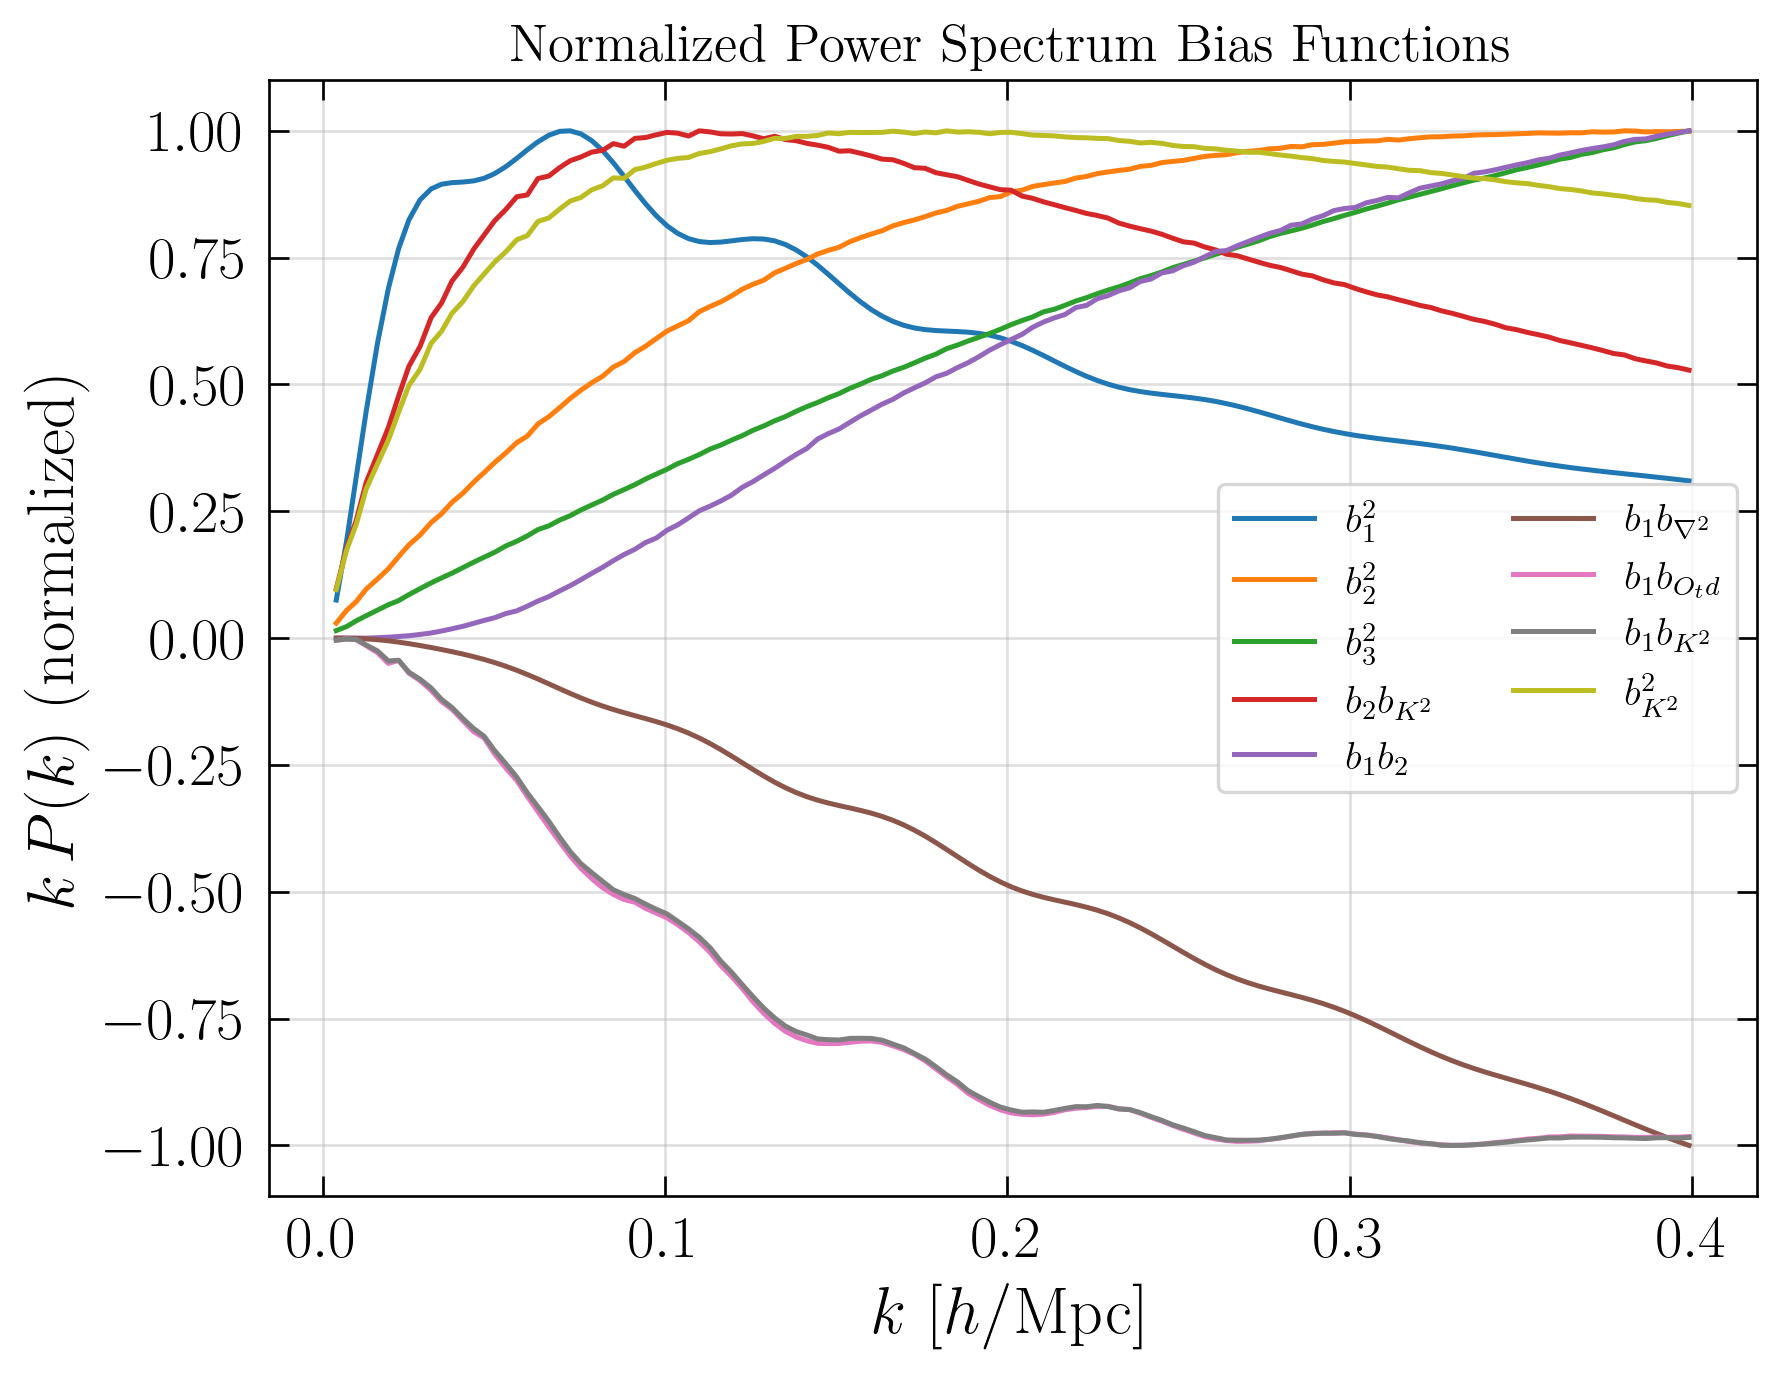

In [12]:
plt.figure(dpi=240)
for i in range(len(all_Ps)):
    y = k*np.average(all_Ps[i], axis=0)
    plt.plot(k, y / np.max(np.abs(y)), label=labels[i])
plt.xlabel(r'$k\ [h/\mathrm{Mpc}]$', fontsize=20)
plt.ylabel(r'$k\,P(k)$ (normalized)', fontsize=20)
plt.title('Normalized Power Spectrum Bias Functions', fontsize=16)
plt.legend(fontsize=12, ncol=2)
plt.grid(alpha=0.4)
plt.show()
plt.close()

In [9]:
# Now test non fixed amplitude simulations
A_P1 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b1b1')
A_P2 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b2b2')
A_P3 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b3b3')
A_PK = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b2K2', symfactor=2)
A_PF = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b2F2', symfactor=2)
A_Pk2 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b1bk2', symfactor=-2) # Negative since its sign is wrong
A_PF3 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b1F3', symfactor=2)
A_PO = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b1Otd', symfactor=2)
A_PK_2 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'b1K2_2', symfactor=2)
A_PK2 = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'K2K2')
A_PFF = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'F2F2')
A_PKF = get_sim_Pk('/mnt/nvme1/kboone/Amplitude_Sims/PowerSpectra/', 'K2F2', symfactor=2)

all_A_Ps = [A_P1+A_PFF+A_PF3, A_P2, A_P3, A_PK, A_PF, A_Pk2, A_PO, A_PK_2+A_PKF, A_PK2]

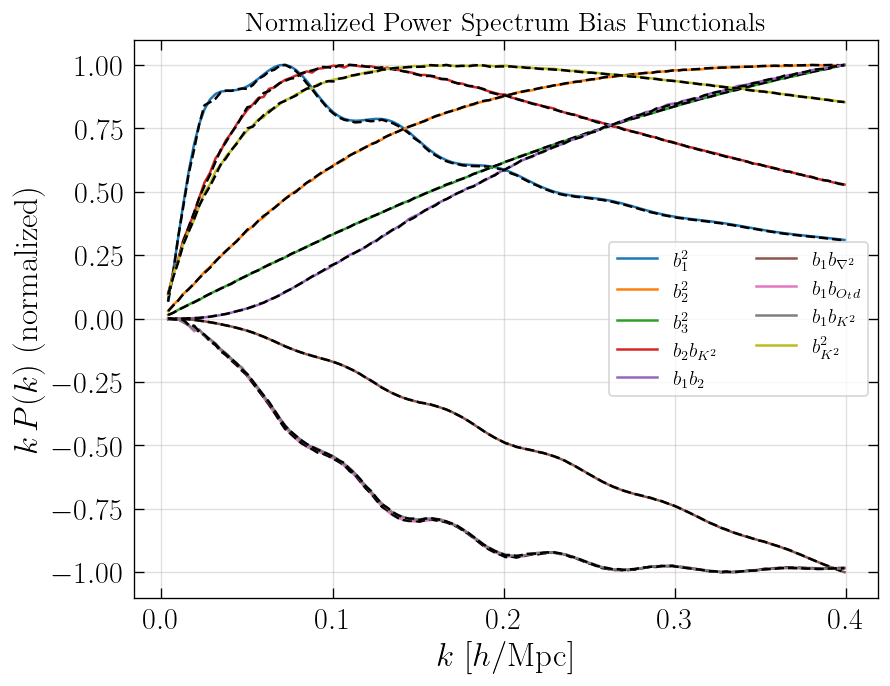

In [10]:
plt.figure(dpi=120)
for i in range(len(all_Ps)):
    y = k*np.average(all_Ps[i], axis=0)
    A_y = k*np.average(all_A_Ps[i], axis=0)
    plt.plot(k, y / np.max(np.abs(y)), label=labels[i], color=cmap(i))
    plt.plot(k, A_y / np.max(np.abs(A_y)), linestyle='--', color='k')
plt.xlabel(r'$k\ [h/\mathrm{Mpc}]$', fontsize=20)
plt.ylabel(r'$k\,P(k)$ (normalized)', fontsize=20)
plt.title('Normalized Power Spectrum Bias Functionals', fontsize=16)
plt.legend(fontsize=12, ncol=2)
plt.grid(alpha=0.4)
plt.show()
plt.close()